# Variationsrechnung

Das Notebook leitet Euler–Lagrange-Gleichung, Beltrami-Identität, Noether-Theorem, Brachistochrone und Geodätengleichung her und prüft sie numerisch: Laufzeiten verschiedener Bahnen und direkte Minimierung für die Brachistochrone, Erhaltungsgrößen mit und ohne Symmetriebruch im Zentralkraftproblem, Geodäten auf der Kugel.

Welche Kurve macht ein Integral über eine Funktion und ihre Ableitung stationär, und was folgt daraus für Erhaltungsgrößen, für die schnellste Rutschbahn und für kürzeste Wege auf einer Kugel?

#### **Hintergrund**

Die gewöhnliche Analysis sucht den Punkt, an dem eine Funktion am kleinsten ist. Die **Variationsrechnung** sucht die Funktion, an der eine Größe am kleinsten ist, die von der ganzen Funktion abhängt: die Kurve mit der kürzesten Laufzeit, die kürzeste Verbindung auf einer gekrümmten Fläche, die Bahn mit der kleinsten Wirkung. Solche Größen heißen **Funktionale**. Die Bedingung für ein Extremum ist keine Gleichung mehr, sondern eine Differentialgleichung, die **Euler–Lagrange-Gleichung**.

Am Anfang stand 1696 Johann Bernoullis Preisfrage nach der **Brachistochrone**, der Kurve, auf der ein Körper am schnellsten von einem Punkt zu einem tieferen gleitet; Newton, Leibniz, Jakob Bernoulli und l'Hôpital lösten sie. Euler (1744) und Lagrange (1755) machten daraus eine allgemeine Methode, Hamilton (1834) formulierte die ganze Mechanik als Prinzip der stationären Wirkung, und Emmy Noether (1918) zeigte, dass jede Symmetrie eine Erhaltungsgröße liefert. Heute ist die Variationsrechnung die Grundlage der analytischen Mechanik, der Optik (Fermats Prinzip), der allgemeinen Relativitätstheorie (Geodäten), der Feldtheorie, der optimalen Steuerung und der Bildverarbeitung (Entrauschen durch Minimieren eines Funktionals). Auch das Training eines neuronalen Netzes ist ein Minimierungsproblem, nur über endlich viele Parameter statt über eine Funktion; die direkte Methode in Experiment 2 schlägt genau diese Brücke.

Landkarte:

- **Das Prinzip**
  - Euler–Lagrange-Gleichung und Beltrami-Identität (Theorie): Ein Funktional ist stationär, wenn eine Differentialgleichung gilt; hängt der Integrand nicht vom Ort ab, gibt es ein erstes Integral.
- **Die Brachistochrone**
  - Laufzeiten verschiedener Bahnen (Exp. 1): Die Zykloide ist schneller als die Gerade und als jede Potenzkurve.
  - Die direkte Methode (Exp. 2): Eine numerische Minimierung über Polygonzüge findet die Zykloide von selbst.
- **Symmetrien und Erhaltungsgrößen**
  - Noether am Zentralkraftproblem (Exp. 3): Zeitliche Symmetrie gibt Energieerhaltung, Drehsymmetrie Drehimpulserhaltung; bricht man die Drehsymmetrie, geht nur der Drehimpuls verloren.
- **Geometrie**
  - Geodäten auf der Kugel (Exp. 4): Die stationären Kurven sind Großkreise, und die Clairaut-Größe bleibt erhalten.

Verwandte Notebooks: Geodäten, Christoffel-Symbole und Krümmung auf allgemeinen Flächen und in der Raumzeit in [Tensor Analysis on Manifolds](https://github.com/deltorobarba/science/blob/main/maths/tensoranalysis.ipynb), Testfunktionen und das Fundamentallemma in [Testfunktionen](https://github.com/deltorobarba/science/blob/main/maths/testfunctions.ipynb), Integratoren für die Bewegungsgleichungen in [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb).

#### **Theorie**

##### *1. Funktionale und stationäre Funktionen*

Ein **Funktional** ordnet einer ganzen Funktion eine Zahl zu, hier $J[y] = \int_a^bL(x, y, y')\,dx$ für Funktionen $y$ mit festen Randwerten $y(a) = y_a$, $y(b) = y_b$; $L$ heißt **Lagrange-Funktion**. Gesucht sind Funktionen, für die $J$ **stationär** ist: Eine kleine **Variation** $y\to y + \epsilon\eta$ mit $\eta(a) = \eta(b) = 0$ ändert $J$ erst in zweiter Ordnung in $\epsilon$, die erste Variation $\delta J = \frac d{d\epsilon}J[y + \epsilon\eta]\big\vert_{\epsilon=0}$ ist null. Minima, Maxima und Sattelpunkte des Funktionals sind stationär.

##### *2. Euler–Lagrange-Gleichung und Beltrami-Identität*

Ableiten unter dem Integral und partielle Integration des Terms mit $\eta'$ (der Randterm verschwindet, weil $\eta$ am Rand null ist) geben
$$\delta J = \int_a^b\Big(\frac{\partial L}{\partial y} - \frac d{dx}\frac{\partial L}{\partial y'}\Big)\eta\,dx .$$
Das muss für jedes $\eta$ verschwinden. Nach dem **Fundamentallemma** (ist $\int h\eta = 0$ für alle glatten $\eta$ mit Randwerten null, ist $h = 0$; man testet mit einem Buckel $\eta\geq0$) folgt die **Euler–Lagrange-Gleichung**
$$\frac{\partial L}{\partial y} - \frac d{dx}\frac{\partial L}{\partial y'} = 0 .$$
**Beltrami-Identität:** Hängt $L$ nicht explizit von $x$ ab, ist $L - y'\,\partial L/\partial y'$ entlang jeder Lösung konstant; die Ableitung dieser Größe ist $\partial L/\partial x$ plus $y'$ mal der Euler–Lagrange-Gleichung. So wird aus einer Gleichung zweiter Ordnung eine erster Ordnung.

##### *3. Mechanik und das Noether-Theorem*

Mit Koordinaten $q_i(t)$ und $L = T - V$ (kinetische minus potentielle Energie) wird die Euler–Lagrange-Gleichung zur Bewegungsgleichung, eine pro Koordinate: das **Prinzip der stationären Wirkung**, $\delta\int L\,dt = 0$.

**Noether-Theorem:** Ist $L$ invariant unter $q\to q + \epsilon K(q)$, so ist $Q = \sum_i\frac{\partial L}{\partial\dot q_i}K_i$ entlang jeder Lösung erhalten. Beweis in einer Zeile: Die Invarianz sagt $\sum_i(\partial_{q_i}L\,K_i + \partial_{\dot q_i}L\,\dot K_i) = 0$, und mit der Euler–Lagrange-Gleichung $\partial_{q_i}L = \frac d{dt}\partial_{\dot q_i}L$ ist die linke Seite $\frac{dQ}{dt}$. Beispiele:
- **Drehung:** Für $L = \tfrac12m(\dot x^2 + \dot y^2) - V(r)$ ist eine kleine Drehung $K = (-y, x)$, und $Q = m(x\dot y - y\dot x) = L_z$, der **Drehimpuls**.
- **Zeitverschiebung:** Hängt $L$ nicht explizit von $t$ ab, ist die **Energie** $H = \sum_i\dot q_i\,\partial L/\partial\dot q_i - L$ erhalten (dieselbe Rechnung wie bei Beltrami); für $L = T - V$ ist $H = T + V$.
- **Verschiebung:** gibt den Impuls.

Bricht ein Zusatzterm im Potential die Drehsymmetrie, hängt aber nicht von der Zeit ab, bleibt die Energie erhalten und der Drehimpuls nicht.

##### *4. Die Brachistochrone*

Ein Körper gleitet reibungsfrei unter der Schwerkraft von $(0, 0)$ nach $(x_1, y_1)$, mit $y$ nach unten. Aus der Energieerhaltung ist $v = \sqrt{2gy}$, und für ein Bogenstück $ds = \sqrt{1 + y'^2}\,dx$ braucht er $dt = ds/v$. Die **Laufzeit**
$$T[y] = \int_0^{x_1}\frac{\sqrt{1 + y'^2}}{\sqrt{2gy}}\,dx$$
hat einen Integranden ohne $x$; Beltrami gibt $y(1 + y'^2) = 2a$ mit einer Konstanten $a$. Die Lösung ist die **Zykloide**
$$x = a(\theta - \sin\theta),\qquad y = a(1 - \cos\theta),$$
die Bahn eines Punktes auf einem rollenden Rad vom Radius $a$. Entlang der Zykloide ist $dt = \sqrt{a/g}\,d\theta$, also $T = \sqrt{a/g}\,\theta_1$. Die Parameter folgen aus dem Endpunkt, $\frac{\theta_1 - \sin\theta_1}{1 - \cos\theta_1} = \frac{x_1}{y_1}$ und $a = y_1/(1 - \cos\theta_1)$. Der tiefste Punkt liegt bei $\theta = \pi$, wo $x/y = \pi/2$ ist; ist $x_1/y_1>\pi/2$, führt die schnellste Bahn unter das Ziel und steigt am Ende wieder an. Dieselbe Kurve ist die **Tautochrone**: Von jedem Startpunkt erreicht ein Körper den tiefsten Punkt in derselben Zeit $\pi\sqrt{a/g}$.

Die **direkte Methode** sucht das Minimum ohne Euler–Lagrange-Gleichung: Man ersetzt die Funktion durch endlich viele Parameter (hier die Höhen eines Polygonzugs) und minimiert numerisch.

##### *5. Geodäten*

Auf einer Fläche mit der **Metrik** $ds^2 = g_{ij}\,dx^idx^j$ sind **Geodäten** die stationären Kurven der Länge. Bequemer ist das **Energiefunktional** $\tfrac12\int g_{ij}\dot x^i\dot x^j\,dt$: Es hat dieselben stationären Kurven und wählt die Parametrisierung mit konstanter Geschwindigkeit (nach Cauchy–Schwarz ist $(\int\vert\dot x\vert dt)^2\leq(t_1 - t_0)\int\vert\dot x\vert^2dt$ mit Gleichheit genau dann). Seine Euler–Lagrange-Gleichungen sind die **Geodätengleichung**
$$\ddot x^k + \Gamma^k_{ij}\,\dot x^i\dot x^j = 0,\qquad\Gamma^k_{ij} = \tfrac12\,g^{kl}\big(\partial_ig_{jl} + \partial_jg_{il} - \partial_lg_{ij}\big),$$
mit den **Christoffel-Symbolen** $\Gamma$. Auf der Einheitskugel ist $ds^2 = d\theta^2 + \sin^2\theta\,d\varphi^2$; die Gleichungen sind $\ddot\theta = \sin\theta\cos\theta\,\dot\varphi^2$ und $\frac d{dt}(\sin^2\theta\,\dot\varphi) = 0$. Weil $\varphi$ nicht vorkommt (Drehsymmetrie um die $z$-Achse), ist nach Noether $c = \sin^2\theta\,\dot\varphi$ erhalten, die **Clairaut-Größe**: Abstand zur Achse mal Geschwindigkeit mal Sinus des Winkels zum Meridian. Der Äquator ist eine Geodäte; weil die Gleichungen unter Drehungen invariant sind, ist jede Geodäte ein gedrehter Äquator, also ein **Großkreis**, der Schnitt der Kugel mit einer Ebene durch den Mittelpunkt.

#### **Code**

Gemeinsame Werkzeuge: die Laufzeit entlang eines Polygonzugs (exakt für gerade Stücke, weil die Beschleunigung dort konstant ist) und die Zykloide durch den Endpunkt $(1, 0.5)$ mit ihrer exakten Laufzeit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, minimize

g = 9.81                       # Erdbeschleunigung in m/s²
x1, y1 = 1.0, 0.5              # Endpunkt in m; y zeigt nach unten


def laufzeit(x, y):
    """Laufzeit entlang des Polygonzugs (x, y), Start in Ruhe bei y = 0.

    Auf jedem geraden Stück ist die Beschleunigung konstant, also ist die Durchschnittsgeschwindigkeit
    der Mittelwert der Geschwindigkeiten an den Enden: dt = 2 ds / (v_a + v_b), exakt für den Polygonzug.
    """
    ds = np.hypot(np.diff(x), np.diff(y))
    v = np.sqrt(2 * g * np.clip(y, 0, None))
    m = ds > 0                                          # Stücke der Länge null überspringen
    return np.sum(2 * ds[m] / (v[1:][m] + v[:-1][m]))


# Zykloide durch den Endpunkt: (theta - sin theta) / (1 - cos theta) = x1 / y1
theta1 = brentq(lambda t: (t - np.sin(t)) / (1 - np.cos(t)) - x1 / y1, 1e-6, 2 * np.pi - 1e-6)
a = y1 / (1 - np.cos(theta1))
T_zykloide = np.sqrt(a / g) * theta1
print(f"Zykloide: a = {a:.4f} m, theta1 = {theta1:.4f} (tiefster Punkt bei theta = pi), T = {T_zykloide:.4f} s")

Zykloide: a = 0.2586 m, theta1 = 3.5084 (tiefster Punkt bei theta = pi), T = 0.5696 s


#### **Experimente**

##### *1. Laufzeiten verschiedener Bahnen*

Wie schnell ist die Zykloide im Vergleich zur Geraden und zu Potenzkurven $y = y_1(x/x_1)^p$? Vorher schätzen: Ist die Gerade, der kürzeste Weg, auch der schnellste?

Die Laufzeit wird für die Zykloide, die Gerade und Potenzkurven mit Exponenten $p$ zwischen 0.15 und 1 von $(0, 0)$ nach $(1, 0.5)$ berechnet, jeweils mit 20 001 Stützstellen, die am Start dicht liegen, wo der Körper noch langsam ist. Für Gerade und Zykloide wird mit den exakten Werten verglichen.

**Hintergrund & Fachbegriffe:**
- **Brachistochrone:** die Kurve, auf der ein Körper unter der Schwerkraft reibungsfrei am schnellsten von einem Punkt zu einem anderen, tieferen gleitet (griechisch „kürzeste Zeit“).
- **Laufzeit-Funktional:** $T[y] = \int ds/v$ mit $v = \sqrt{2gy}$ aus der Energieerhaltung; eine Zahl für jede Kurve.
- **Zykloide:** die Bahn eines Punktes auf dem Rand eines rollenden Rades, $x = a(\theta - \sin\theta)$, $y = a(1 - \cos\theta)$.
- **Potenzkurven:** $y = y_1(x/x_1)^p$ durch beide Endpunkte; kleine $p$ fallen am Anfang steil ab, $p = 1$ ist die Gerade.

Kontrolle: Gerade numerisch 0.71392 s, exakt 0.71392 s
Kontrolle: Zykloide numerisch 0.56962 s, exakt 0.56962 s


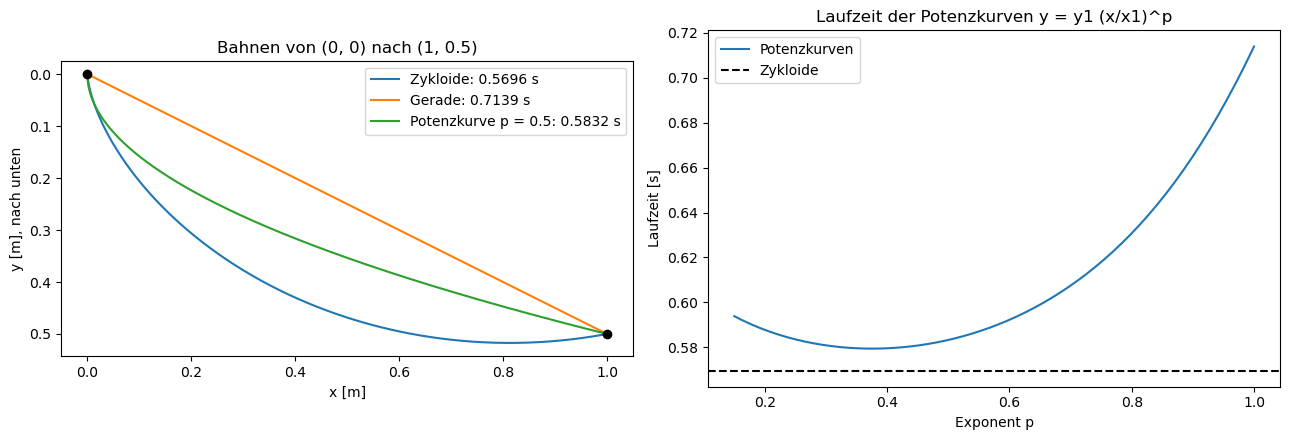

In [2]:
s = np.linspace(0, 1, 20001) ** 2                     # Stützstellen, dicht am Start
th = theta1 * np.linspace(0, 1, 20001)                  # die Zykloide ist in theta schon dicht am Start
bahnen = {
    "Zykloide": (a * (th - np.sin(th)), a * (1 - np.cos(th))),
    "Gerade": (x1 * s, y1 * s),
    "Potenzkurve p = 0.5": (x1 * s, y1 * s ** 0.5),
}

T_gerade_exakt = np.sqrt(2 * (x1**2 + y1**2) / (g * y1))
print(f"Kontrolle: Gerade numerisch {laufzeit(*bahnen['Gerade']):.5f} s, exakt {T_gerade_exakt:.5f} s")
print(f"Kontrolle: Zykloide numerisch {laufzeit(*bahnen['Zykloide']):.5f} s, exakt {T_zykloide:.5f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (x, y) in bahnen.items():
    ax1.plot(x, y, label=f"{name}: {laufzeit(x, y):.4f} s")
ax1.plot([0, x1], [0, y1], "ko")
ax1.invert_yaxis()
ax1.set_aspect("equal")
ax1.set_xlabel("x [m]")
ax1.set_ylabel("y [m], nach unten")
ax1.set_title("Bahnen von (0, 0) nach (1, 0.5)")
ax1.legend()

exponenten = np.linspace(0.15, 1.0, 60)
zeiten = [laufzeit(x1 * s, y1 * s ** p) for p in exponenten]
ax2.plot(exponenten, zeiten, label="Potenzkurven")
ax2.axhline(T_zykloide, color="k", ls="--", label="Zykloide")
ax2.set_xlabel("Exponent p")
ax2.set_ylabel("Laufzeit [s]")
ax2.set_title("Laufzeit der Potenzkurven y = y1 (x/x1)^p")
ax2.legend()
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt drei Bahnen von $(0, 0)$ nach $(1, 0.5)$ (die $y$-Achse zeigt nach unten). Die Gerade ist der kürzeste Weg, braucht aber $0.7139$ s; die Potenzkurve mit $p = 0.5$ fällt am Anfang steiler und braucht $0.5832$ s; die Zykloide fällt am steilsten, taucht sogar etwas unter das Ziel und steigt am Ende wieder an, mit der kürzesten Zeit $0.5696$ s. Steil am Anfang lohnt sich, weil der Körper dann früh schnell wird.
* Das **rechte Bild** zeigt die Laufzeit aller Potenzkurven gegen ihren Exponenten: Die beste liegt bei $p\approx0.38$ mit etwa $0.58$ s, immer noch über der Zykloide (gestrichelt). Keine Potenzkurve erreicht sie.
* Die **Ausgabe** bestätigt die Rechnung: Die numerische Laufzeit stimmt für Gerade ($0.71392$ s) und Zykloide ($0.56962$ s) auf fünf Stellen mit den exakten Werten überein. Die Zykloide hat $a = 0.2586$ m und $\theta_1 = 3.508>\pi$; deshalb liegt ihr tiefster Punkt vor dem Ziel ($x_1/y_1 = 2>\pi/2$).

##### *2. Die direkte Methode*

Findet eine numerische Minimierung der Laufzeit über alle Polygonzüge von selbst die Zykloide, ohne die Euler–Lagrange-Gleichung zu kennen? Die Unbekannten sind die $y$-Werte an festen $x$-Stellen; gestartet wird mit der Geraden. Vorher überlegen: Wird die gefundene Laufzeit größer oder kleiner als die der Zykloide sein?

Der Polygonzug hat 80 innere Punkte, deren $x$-Stellen am Start dicht liegen. Die Laufzeit wird mit L-BFGS-B über die 80 Höhen minimiert, mit der Nebenbedingung $y>0$.

**Hintergrund & Fachbegriffe:**
- **Direkte Methode:** Man sucht das Minimum eines Funktionals unmittelbar, statt die Euler–Lagrange-Gleichung zu lösen: Die Funktion wird durch endlich viele Parameter ersetzt, und ein Optimierer verbessert sie Schritt für Schritt.
- **Polygonzug:** eine Kette gerader Stücke durch vorgegebene Punkte; mit genügend vielen Punkten nähert er jede glatte Kurve.
- **L-BFGS-B:** ein Quasi-Newton-Verfahren mit begrenztem Speicher, das Schranken für die Variablen erlaubt; dasselbe Prinzip wie beim Training großer Modelle mit Gradienten.

Minimierung: T = 0.56964 s nach 165 Schritten, Zykloide exakt 0.56962 s


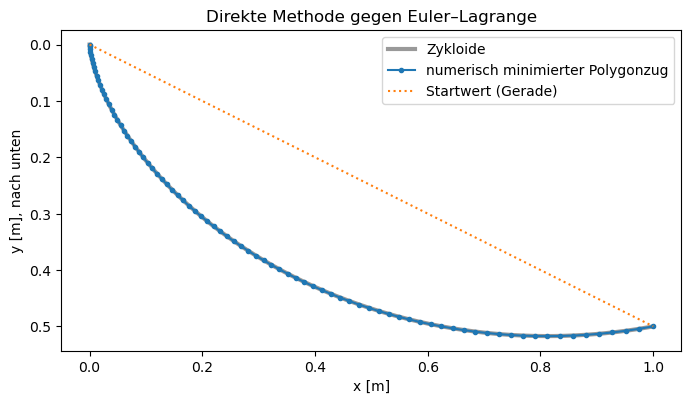

In [3]:
n = 80
x_gitter = x1 * np.linspace(0, 1, n + 2) ** 2           # dicht am Start, wo die Bahn steil ist


def zeit_von(y_innen):
    y = np.concatenate([[0.0], y_innen, [y1]])
    return laufzeit(x_gitter, y)


start = y1 * x_gitter[1:-1] / x1
ergebnis = minimize(zeit_von, start, method="L-BFGS-B", bounds=[(1e-9, None)] * n, options={"maxiter": 5000})
y_opt = np.concatenate([[0.0], ergebnis.x, [y1]])
print(f"Minimierung: T = {ergebnis.fun:.5f} s nach {ergebnis.nit} Schritten, Zykloide exakt {T_zykloide:.5f} s")

fig, ax = plt.subplots(figsize=(8, 4.5))
th = np.linspace(0, theta1, 400)
ax.plot(a * (th - np.sin(th)), a * (1 - np.cos(th)), "k-", lw=3, alpha=0.4, label="Zykloide")
ax.plot(x_gitter, y_opt, "o-", ms=3, label="numerisch minimierter Polygonzug")
ax.plot(x_gitter, y1 * x_gitter / x1, ":", label="Startwert (Gerade)")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m], nach unten")
ax.set_title("Direkte Methode gegen Euler–Lagrange")
ax.legend()
plt.show()

* Das **Bild** zeigt den Startwert (die Gerade, gepunktet), die Zykloide (grau, breit) und den numerisch gefundenen Polygonzug (blau mit Punkten). Der Polygonzug liegt auf der ganzen Länge auf der Zykloide, auch dort, wo sie unter das Ziel taucht.
* Die **Ausgabe** gibt die Laufzeit des Polygonzugs, $0.56964$ s nach 165 Schritten, gegen $0.56962$ s für die Zykloide. Der Polygonzug ist minimal langsamer, weil er die Kurve nur mit 81 geraden Stücken nachbildet; er kann die Zykloide nicht unterbieten, weil sie das Minimum über alle Kurven ist.

##### *3. Noether am Zentralkraftproblem*

Ein Teilchen bewegt sich im Potential $V = -1/r$ und einmal zusätzlich in $\frac\epsilon2(x^2 - y^2)$, das die Drehsymmetrie bricht, aber nicht von der Zeit abhängt. Welche Größe bleibt jeweils erhalten, Energie oder Drehimpuls? Vorher aus dem Noether-Theorem vorhersagen.

Die Bewegungsgleichungen werden mit $\epsilon = 0$ und $\epsilon = 0.01$ vom selben Anfangszustand $(1, 0)$ mit Geschwindigkeit $(0, 0.8)$ bis $t = 60$ sehr genau integriert (DOP853, relative Toleranz $10^{-11}$). Gezeigt werden die Bahnen, die Energie und der Drehimpuls.

**Hintergrund & Fachbegriffe:**
- **Zentralkraftproblem:** Bewegung in einem Potential, das nur vom Abstand $r$ abhängt, wie ein Planet um die Sonne; bei $V = -1/r$ sind die Bahnen Ellipsen (Kepler).
- **Symmetrie und Erhaltungsgröße:** Nach Noether gehört zu jeder kontinuierlichen Symmetrie der Lagrange-Funktion eine erhaltene Größe: Zeitverschiebung zur Energie, Drehung zum Drehimpuls $L_z = x\dot y - y\dot x$.
- **Symmetriebruch:** Der Zusatzterm $\frac\epsilon2(x^2 - y^2)$ ist in $x$- und $y$-Richtung verschieden, also nicht drehsymmetrisch, aber zeitlich konstant.
- **Periheldrehung:** Eine kleine Störung der $1/r$-Kraft lässt die Ellipse nicht mehr geschlossen; ihre Achse dreht sich oder ihre Form ändert sich langsam.

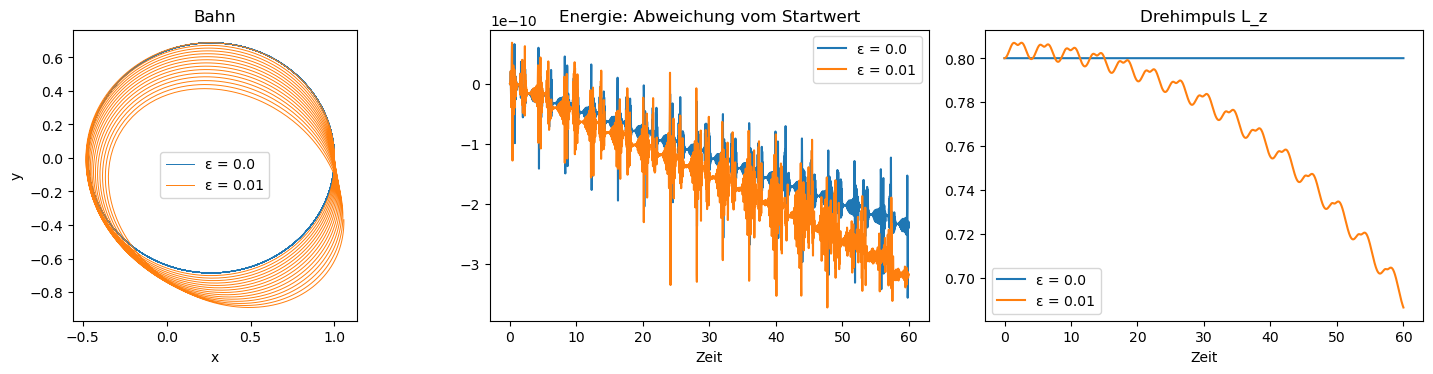

In [4]:
def bewegung(t, z, eps):
    x, y, vx, vy = z
    r3 = (x**2 + y**2) ** 1.5
    return [vx, vy, -x / r3 - eps * x, -y / r3 + eps * y]


def energie(z, eps):
    x, y, vx, vy = z
    return 0.5 * (vx**2 + vy**2) - 1 / np.hypot(x, y) + 0.5 * eps * (x**2 - y**2)


def drehimpuls(z):
    x, y, vx, vy = z
    return x * vy - y * vx


z0 = [1.0, 0.0, 0.0, 0.8]
t = np.linspace(0, 60, 3000)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for eps, farbe in [(0.0, "C0"), (0.01, "C1")]:
    lsg = solve_ivp(bewegung, (0, 60), z0, t_eval=t, args=(eps,), method="DOP853", rtol=1e-11, atol=1e-12)
    axes[0].plot(lsg.y[0], lsg.y[1], color=farbe, lw=0.7, label=f"ε = {eps}")
    axes[1].plot(t, energie(lsg.y, eps) - energie(z0, eps), color=farbe, label=f"ε = {eps}")
    axes[2].plot(t, drehimpuls(lsg.y), color=farbe, label=f"ε = {eps}")
axes[0].set_aspect("equal")
axes[0].set_title("Bahn")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[1].set_title("Energie: Abweichung vom Startwert")
axes[1].set_xlabel("Zeit")
axes[2].set_title("Drehimpuls L_z")
axes[2].set_xlabel("Zeit")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Bahnen: Ohne Störung (blau) läuft das Teilchen 60 Zeiteinheiten lang auf derselben Ellipse, die Bahnen liegen genau aufeinander. Mit Störung (orange) schließt sich die Bahn nicht mehr: Die Ellipse dreht sich von Umlauf zu Umlauf ein Stück weiter (im Bild nach unten) und ändert dabei ihre Form.
* Das **mittlere Bild** zeigt die Abweichung der Energie vom Startwert: In beiden Fällen bleibt sie unter $4\cdot10^{-10}$, das ist der Integrationsfehler. Die Energie ist erhalten, weil keines der beiden Potentiale von der Zeit abhängt.
* Das **rechte Bild** zeigt den Drehimpuls: Ohne Störung bleibt er exakt bei $0.8$; mit Störung steigt er zuerst leicht auf etwa $0.806$, schwankt dann bei jedem Umlauf und fällt bis $t = 60$ auf etwa $0.69$. Genau wie Noether vorhersagt: Die gebrochene Drehsymmetrie kostet die Drehimpulserhaltung, die erhaltene Zeitsymmetrie lässt die Energieerhaltung bestehen.

##### *4. Geodäten auf der Kugel*

Liegt eine numerisch integrierte Geodäte in einer Ebene durch den Mittelpunkt, und bleibt die Clairaut-Größe $c = \sin^2\theta\,\dot\varphi$ konstant? Vorher vorhersagen: Wie weit kommt die Geodäte nach Norden, wenn $c$ erhalten ist?

Die Geodätengleichungen der Einheitskugel werden vom Punkt $\theta = 1$, $\varphi = 0$ mit der Richtung $(\dot\theta, \dot\varphi) = (0.3, 1)$ eine volle Runde integriert. Für jeden Punkt wird der Abstand von der Ebene durch den Mittelpunkt bestimmt, die Startpunkt und Startrichtung aufspannen, und $c$ ausgewertet.

**Hintergrund & Fachbegriffe:**
- **Geodäte:** eine Kurve, die lokal der kürzeste Weg ist; auf der Kugel ein **Großkreis**, der Schnitt mit einer Ebene durch den Mittelpunkt (wie die Flugrouten auf langen Strecken).
- **Geodätengleichung und Christoffel-Symbole:** die Euler–Lagrange-Gleichungen des Energiefunktionals; die Christoffel-Symbole enthalten die Ableitungen der Metrik und beschreiben, wie sich die Koordinaten auf der gekrümmten Fläche drehen.
- **Clairaut-Größe:** $c = \sin^2\theta\,\dot\varphi$, erhalten wegen der Drehsymmetrie um die Polachse (Noether). Weil $\sin\theta$ bei konstanter Geschwindigkeit nicht kleiner werden kann als $c$/Geschwindigkeit, hat jeder Großkreis einen nördlichsten Punkt.

größter Abstand von der Ebene durch den Mittelpunkt: 3.0e-11
Clairaut-Größe c: von 0.7080734183 bis 0.7080734183


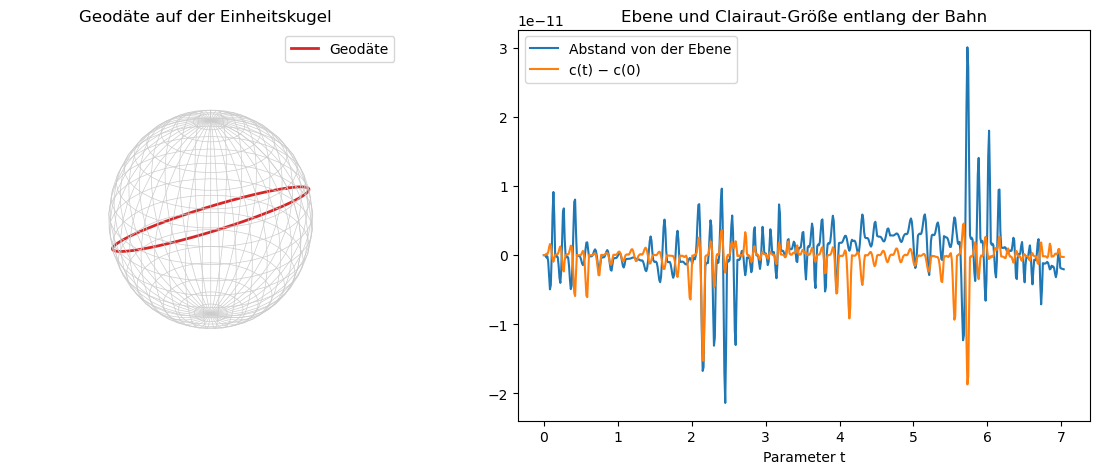

In [5]:
def geodaete(t, z):
    th, ph, dth, dph = z
    return [dth, dph, np.sin(th) * np.cos(th) * dph**2, -2 / np.tan(th) * dth * dph]


z0 = [1.0, 0.0, 0.3, 1.0]                                  # theta, phi, ihre Ableitungen
tempo = np.sqrt(z0[2] ** 2 + np.sin(z0[0]) ** 2 * z0[3] ** 2)
t = np.linspace(0, 2 * np.pi / tempo, 600)                 # eine volle Runde
lsg = solve_ivp(geodaete, (0, t[-1]), z0, t_eval=t, method="DOP853", rtol=1e-11, atol=1e-12)
th, ph, dth, dph = lsg.y
punkte = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])

# Normale der Ebene aus Startpunkt und Startrichtung
r0 = punkte[:, 0]
v0 = np.array([np.cos(th[0]) * np.cos(ph[0]) * dth[0] - np.sin(th[0]) * np.sin(ph[0]) * dph[0],
               np.cos(th[0]) * np.sin(ph[0]) * dth[0] + np.sin(th[0]) * np.cos(ph[0]) * dph[0],
               -np.sin(th[0]) * dth[0]])
normale = np.cross(r0, v0) / np.linalg.norm(np.cross(r0, v0))
abstand = normale @ punkte
c = np.sin(th) ** 2 * dph
print(f"größter Abstand von der Ebene durch den Mittelpunkt: {np.abs(abstand).max():.1e}")
print(f"Clairaut-Größe c: von {c.min():.10f} bis {c.max():.10f}")

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
u, w = np.meshgrid(np.linspace(0, 2 * np.pi, 40), np.linspace(0, np.pi, 20))
ax.plot_wireframe(np.cos(u) * np.sin(w), np.sin(u) * np.sin(w), np.cos(w), color="0.8", lw=0.5)
ax.plot(*punkte, color="C3", lw=2, label="Geodäte")
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.set_title("Geodäte auf der Einheitskugel")
ax.legend()
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t, abstand, label="Abstand von der Ebene")
ax2.plot(t, c - c[0], label="c(t) − c(0)")
ax2.set_xlabel("Parameter t")
ax2.set_title("Ebene und Clairaut-Größe entlang der Bahn")
ax2.legend()
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Geodäte (rot) auf der Kugel: ein geneigter Großkreis, der nach einer Runde in sich zurückläuft. Er schneidet den Äquator und erreicht im Norden und Süden gleich hohe Breiten. Der nördlichste Punkt folgt aus der Clairaut-Größe: $\sin\theta_{\min} = c/v = 0.708/0.893\approx0.79$, also $\theta_{\min}\approx0.915$, etwa $37.6^\circ$ nördlicher Breite.
* Das **rechte Bild** zeigt den Abstand der Bahn von der Ebene durch den Mittelpunkt (blau) und die Änderung der Clairaut-Größe (orange) entlang der Bahn. Beide bleiben unter $3\cdot10^{-11}$, also null bis auf den Fehler der Integration.
* Die **Ausgabe** gibt den größten Abstand $3.0\cdot10^{-11}$ und $c = 0.7080734183$ über die ganze Bahn, auf zehn Stellen konstant. Die numerische Lösung der Euler–Lagrange-Gleichungen ist also ein Großkreis, und die Noether-Größe der Drehsymmetrie ist erhalten.

#### **Ergebnis**

Beim Lauf vom 2026-10-19:

- **Laufzeiten:** Von $(0, 0)$ nach $(1, 0.5)$ braucht die Gerade $0.7139$ s, die Potenzkurve mit $p = 0.5$ $0.5832$ s, die beste Potenzkurve ($p\approx0.38$) etwa $0.58$ s und die Zykloide $0.5696$ s. Die numerische Laufzeit stimmt für Gerade und Zykloide auf fünf Stellen mit den exakten Werten überein. Weil $x_1/y_1 = 2>\pi/2$ ist, taucht die Zykloide unter das Ziel ($\theta_1 = 3.508>\pi$).
- **Direkte Methode:** Die Minimierung über Polygonzüge mit 80 freien Höhen findet nach 165 Schritten $0.56964$ s und liegt sichtbar auf der Zykloide ($0.56962$ s), ohne die Euler–Lagrange-Gleichung zu kennen.
- **Noether:** In beiden Potentialen bleibt die Energie bis auf $4\cdot10^{-10}$ erhalten. Der Drehimpuls bleibt ohne Störung exakt bei 0.8; mit der Störung $\epsilon = 0.01$, die die Drehsymmetrie bricht, fällt er bis $t = 60$ auf etwa 0.69, und die Ellipse verändert sich von Umlauf zu Umlauf.
- **Geodäten:** Die integrierte Geodäte weicht höchstens $3\cdot10^{-11}$ von einer Ebene durch den Mittelpunkt ab, ist also ein Großkreis, und die Clairaut-Größe ist auf zehn Stellen konstant ($0.7080734183$).

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. *Tautochrone.* Startet der Körper in Ruhe an einem beliebigen Punkt der Zykloide, erreicht er den tiefsten Punkt immer nach derselben Zeit $\pi\sqrt{a/g}$. Prüfe das mit einer angepassten `laufzeit`, in der die Geschwindigkeit $\sqrt{2g(y - y_0)}$ ist.
2. Wähle einen Endpunkt mit $x_1/y_1<\pi/2$. Taucht die Zykloide jetzt unter das Ziel? Wie ändert sich die Laufzeitkurve der Potenzkurven?
3. Lasse $\epsilon$ in Experiment 3 mit der Zeit schwingen, $\epsilon(t) = 0{,}01\cos t$. Welche Erhaltungsgröße geht verloren?
4. Geodäten auf dem Torus: Leite die Metrik $ds^2 = (R + r\cos v)^2du^2 + r^2dv^2$ her, bestimme die Christoffel-Symbole, integriere und prüfe die Clairaut-Größe $(R + r\cos v)^2\dot u$.

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist ein Funktional, und was heißt es, dass es stationär ist?</summary>

Eine Vorschrift, die einer ganzen Funktion eine Zahl zuordnet, etwa $J[y] = \int L(x, y, y')\,dx$. Stationär heißt: Kleine Änderungen $y + \epsilon\eta$ mit festen Randwerten ändern $J$ erst in zweiter Ordnung.
</details>

<details><summary>2. Wie kommt man zur Euler–Lagrange-Gleichung?</summary>

Man leitet $J[y + \epsilon\eta]$ nach $\epsilon$ ab, integriert den Term mit $\eta'$ partiell (der Randterm fällt weg) und verlangt, dass das Integral für jedes $\eta$ verschwindet. Nach dem Fundamentallemma muss der Faktor vor $\eta$ null sein: $\partial L/\partial y - \frac d{dx}\partial L/\partial y' = 0$.
</details>

<details><summary>3. Was sagt die Beltrami-Identität, und wann hilft sie?</summary>

Hängt $L$ nicht von $x$ ab, ist $L - y'\,\partial L/\partial y'$ konstant. Das macht aus einer Gleichung zweiter Ordnung eine erster Ordnung, etwa bei der Brachistochrone.
</details>

<details><summary>4. Was besagt das Noether-Theorem, und welche Erhaltungsgrößen gehören zu Zeitverschiebung und Drehung?</summary>

Jede kontinuierliche Symmetrie der Lagrange-Funktion liefert eine Erhaltungsgröße $Q = \sum\partial L/\partial\dot q_i\,K_i$. Zeitverschiebung gibt die Energie, Drehung den Drehimpuls, Verschiebung den Impuls.
</details>

<details><summary>5. Warum ist die Zykloide schneller als die Gerade, obwohl sie länger ist?</summary>

Sie fällt am Anfang steil, sodass der Körper früh große Geschwindigkeit gewinnt und den längeren Weg schneller zurücklegt. Die Euler–Lagrange-Gleichung findet genau den besten Kompromiss zwischen Länge und Geschwindigkeit.
</details>

<details><summary>6. Wann taucht die schnellste Bahn unter das Ziel?</summary>

Wenn $x_1/y_1>\pi/2$ ist: Der tiefste Punkt der Zykloide liegt bei $\theta = \pi$, und das Ziel liegt dahinter.
</details>

<details><summary>7. Was ist die direkte Methode, und was hat sie mit maschinellem Lernen zu tun?</summary>

Man ersetzt die gesuchte Funktion durch endlich viele Parameter und minimiert das Funktional numerisch, ohne die Euler–Lagrange-Gleichung zu lösen. Das Training eines neuronalen Netzes ist dasselbe: ein Funktional über eine parametrisierte Funktion, minimiert mit Gradienten.
</details>

<details><summary>8. Warum benutzt man für Geodäten das Energiefunktional statt der Länge?</summary>

Die Länge hängt nicht von der Parametrisierung ab, ihre Gleichungen legen den Parameter nicht fest. Das Energiefunktional hat dieselben stationären Kurven und wählt die Parametrisierung mit konstanter Geschwindigkeit.
</details>

<details><summary>9. Warum sind die Geodäten der Kugel Großkreise, und was ist die Clairaut-Größe?</summary>

Der Äquator ist eine Geodäte, und die Gleichungen sind drehsymmetrisch, also ist jede Geodäte ein gedrehter Äquator. Die Clairaut-Größe $\sin^2\theta\,\dot\varphi$ ist die Noether-Größe der Drehung um die Polachse.
</details>

#### **Nächste Schritte**

- **Zweite Variation:** Ob ein stationärer Punkt wirklich ein Minimum ist, entscheidet die zweite Variation (Legendre- und Jacobi-Bedingung, konjugierte Punkte); auf der Kugel ist ein Großkreisbogen länger als ein halber Umfang kein kürzester Weg mehr.
- **Nebenbedingungen:** Lagrange-Multiplikatoren für Funktionale, etwa das isoperimetrische Problem (größte Fläche bei fester Länge, Ergebnis: der Kreis) und die Kettenlinie.
- **Hamilton-Formalismus:** Legendre-Transformation zu Impulsen und Hamilton-Gleichungen; symplektische Integratoren im Notebook [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb).
- **Feldtheorie:** Funktionale über Felder statt Kurven; die Euler–Lagrange-Gleichungen geben Wellengleichung, Maxwell-Gleichungen und Einstein-Gleichungen.
- **Optimale Steuerung:** das Pontrjaginsche Maximumprinzip und gradientenbasiertes Pulsdesign für Quantengatter.
- **Gekrümmte Räume:** Geodäten, Paralleltransport und Krümmung in [Tensor Analysis on Manifolds](https://github.com/deltorobarba/science/blob/main/maths/tensoranalysis.ipynb).

#### **Referenzen**

- I. M. Gelfand, S. V. Fomin: *Calculus of Variations*, Kapitel 1 (die Euler–Lagrange-Gleichung).
- L. D. Landau, E. M. Lifschitz: *Lehrbuch der theoretischen Physik, Band I: Mechanik*, §§ 2, 6, 7 und 9 (Prinzip der kleinsten Wirkung, Energie, Impuls, Drehimpuls).
- M. P. do Carmo: *Differential Geometry of Curves and Surfaces*, Abschnitt 4-4 (Geodäten, Clairaut-Relation).